# **Lab Assignment: Landmark Recognition Using the SIFT Algorithm**


In [1]:
import importlib, subprocess, sys

def _ensure_sift():
    # Install opencv-contrib only if cv2.SIFT_create is unavailable (not needed on current Colab).
    import cv2
    if hasattr(cv2, 'SIFT_create'):
        return cv2
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'opencv-contrib-python-headless'], check=True)
    return importlib.reload(cv2)

cv2 = _ensure_sift()

import os, json, time, shutil, zipfile, warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from IPython.display import display, Markdown

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f'OpenCV {cv2.__version__} | NumPy {np.__version__} | pandas {pd.__version__} | Colab: {IN_COLAB}')
assert hasattr(cv2, 'SIFT_create'), 'SIFT is not available in this OpenCV build.'

OpenCV 5.0.0 | NumPy 2.1.3 | pandas 2.2.3 | Colab: True


### 4.1 Experiment configuration
Every tunable quantity lives here, with its justification, so that no unexplained constants appear later in the code.

In [2]:
# ---------------------------------------------------------------- reproducibility
SEED = 42
np.random.seed(SEED)
cv2.setRNGSeed(SEED)            # makes OpenCV's RANSAC sampling repeatable

# ---------------------------------------------------------------- data location
# 'wikimedia' : download freely licensed photos from Wikimedia Commons (default)
# 'drive'     : copy your own dataset from Google Drive (same folder layout, see Section 5)
# 'existing'  : DATA_ROOT already contains the dataset
DATA_SOURCE     = os.environ.get('LAB_DATA_SOURCE', 'wikimedia')
DATA_ROOT       = Path(os.environ.get('LAB_DATA_ROOT', '/content/landmark_lab' if IN_COLAB else 'landmark_lab'))
DRIVE_DATA_ROOT = '/content/drive/MyDrive/landmark_lab'   # used only when DATA_SOURCE == 'drive'
FORCE_DOWNLOAD  = False                                   # True = discard cached images and download again

DB_DIR      = DATA_ROOT / 'landmark_db'          # landmark_db/<Landmark_Name>/ref_XX.jpg
HOLDOUT_DIR = DATA_ROOT / 'queries' / 'holdout'  # queries/holdout/<Landmark_Name>.jpg (never in the DB)
UNKNOWN_DIR = DATA_ROOT / 'queries' / 'unknown'  # queries/unknown/*.jpg (landmarks not in the DB)
OUT_DIR     = DATA_ROOT / 'outputs'
FIG_DIR     = OUT_DIR / 'screenshots'

# Search phrases per landmark, tried in order until enough photos are found.
LANDMARK_QUERIES = {
    'Eiffel_Tower':        ['Eiffel Tower Paris', 'Tour Eiffel Champ de Mars'],
    'Taj_Mahal':           ['Taj Mahal Agra', 'Taj Mahal front view'],
    'Colosseum':           ['Colosseum Rome exterior', 'Colosseo Roma'],
    'Statue_of_Liberty':   ['Statue of Liberty New York', 'Statue of Liberty Liberty Island'],
    'Great_Wall_of_China': ['Great Wall of China Mutianyu', 'Great Wall of China Badaling'],
}
UNKNOWN_QUERIES = {'Sydney_Opera_House': ['Sydney Opera House', 'Sydney Opera House harbour']}
N_REFERENCE = 5    # reference photos per landmark in the database
N_HOLDOUT   = 1    # held-out photo per landmark (real different-viewpoint query)
N_UNKNOWN   = 2    # photos of the landmark that is NOT in the database
THUMB_WIDTH = 960  # Wikimedia serves pre-rendered thumbnails at standard widths such as 960 px

# ---------------------------------------------------------------- preprocessing / SIFT
MAX_IMAGE_DIM   = 800    # longest side after loading; bounds runtime while keeping detail
SIFT_N_FEATURES = 2000   # keep the 2000 strongest keypoints per image (0 would mean 'all')

# ---------------------------------------------------------------- matching / decision
LOWE_RATIO              = 0.75  # ratio-test threshold tau (Section 2.4)
MIN_GOOD_MATCHES        = 20    # T_m: minimum reliable matches to accept a candidate
MIN_INLIERS             = 15    # T_i: minimum RANSAC inliers to accept a candidate
MIN_HOMOGRAPHY_MATCHES  = 10    # below this RANSAC is not attempted (4 is the mathematical minimum)
RANSAC_REPROJ_THRESHOLD = 5.0   # px; inlier if reprojection error < 5 px
TOP_K_VERIFY            = 3     # candidates that receive geometric verification

# ---------------------------------------------------------------- evaluation conditions
ROTATION_DEG      = 45
RESIZE_FACTOR     = 0.5
BRIGHTNESS_FACTOR = 0.35
PERSPECTIVE_SHIFT = 0.18   # fraction of width by which the top corners move inward

# ---------------------------------------------------------------- plotting
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ACCEPT_COLOR, REJECT_COLOR, MUTED = '#0ca30c', '#d03b3b', '#9a9993'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10, 'axes.titlesize': 11,
    'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

for d in (DB_DIR, HOLDOUT_DIR, UNKNOWN_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
assert 0 < LOWE_RATIO < 1 and MIN_HOMOGRAPHY_MATCHES >= 4
print('Data root:', DATA_ROOT.resolve(), '| source:', DATA_SOURCE)

Data root: /content/landmark_lab | source: wikimedia


## 5. Data Acquisition and Preparation — *Task 1: Landmark Image Database*



In [3]:
COMMONS_API = 'https://commons.wikimedia.org/w/api.php'
HTTP_HEADERS = {'User-Agent': 'SIFT-Landmark-Lab/1.0 (university coursework; Google Colab notebook)'}

def commons_search(query: str, limit: int = 40) -> list:
    '''Return candidate photos (title, thumbnail URL, source page) for a Wikimedia Commons search.'''
    params = {
        'action': 'query', 'format': 'json', 'generator': 'search',
        'gsrsearch': f'{query} filetype:bitmap', 'gsrnamespace': 6, 'gsrlimit': limit,
        'prop': 'imageinfo', 'iiprop': 'url|size|mime', 'iiurlwidth': THUMB_WIDTH,
    }
    r = requests.get(COMMONS_API, params=params, headers=HTTP_HEADERS, timeout=30)
    r.raise_for_status()
    pages = sorted(r.json().get('query', {}).get('pages', {}).values(), key=lambda p: p.get('index', 10**9))
    candidates = []
    for p in pages:
        info = (p.get('imageinfo') or [{}])[0]
        w, h = info.get('width', 0), info.get('height', 0)
        if info.get('mime') != 'image/jpeg' or min(w, h) < 500 or not (0.5 <= w / max(h, 1) <= 2.0):
            continue                                    # photographs only, no tiny or panoramic files
        candidates.append({'title': p['title'], 'url': info.get('thumburl') or info.get('url'),
                           'source_page': info.get('descriptionurl', '')})
    return candidates

def fetch_image(url: str, retries: int = 4) -> Optional[np.ndarray]:
    '''Download and decode an image; polite exponential back-off on rate limiting.'''
    for attempt in range(retries):
        try:
            r = requests.get(url, headers=HTTP_HEADERS, timeout=40)
            if r.status_code in (429, 500, 502, 503, 504):
                time.sleep(2 ** (attempt + 1)); continue
            r.raise_for_status()
            img = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
            return img
        except requests.RequestException:
            time.sleep(2 ** (attempt + 1))
    return None

def tiny_signature(img: np.ndarray) -> np.ndarray:
    '''16x16 grayscale thumbnail used to detect near-duplicate downloads.'''
    return cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (16, 16), interpolation=cv2.INTER_AREA).astype(np.float32)

def collect_photos(name: str, queries: list, n_needed: int, existing: list) -> list:
    '''Return up to n_needed new (image, record) pairs that are not duplicates of `existing` images.'''
    seen_sigs = [tiny_signature(im) for im in existing]
    picked, seen_titles = [], set()
    for q in queries:
        try:
            candidates = commons_search(q)
        except requests.RequestException as e:
            print(f'  search failed for "{q}": {e}'); continue
        for c in candidates:
            if len(picked) >= n_needed:
                return picked
            if c['title'] in seen_titles:
                continue
            seen_titles.add(c['title'])
            img = fetch_image(c['url'])
            time.sleep(0.3)                              # be polite to the public API
            if img is None or min(img.shape[:2]) < 300:
                continue
            sig = tiny_signature(img)
            if any(np.mean(np.abs(sig - s)) < 6 for s in seen_sigs):
                continue                                 # near-duplicate of an image we already have
            seen_sigs.append(sig)
            picked.append((img, {'landmark': name, 'query': q, **c}))
    return picked

def build_dataset_from_wikimedia():
    manifest_path = OUT_DIR / 'image_manifest.csv'
    manifest = pd.read_csv(manifest_path).to_dict('records') if manifest_path.exists() else []
    for name, queries in LANDMARK_QUERIES.items():
        folder = DB_DIR / name
        folder.mkdir(parents=True, exist_ok=True)
        refs = sorted(folder.glob('*.jpg'))
        holdout = HOLDOUT_DIR / f'{name}.jpg'
        need = (N_REFERENCE - len(refs)) + (0 if holdout.exists() else N_HOLDOUT)
        if need <= 0:
            print(f'{name:22s} cached ({len(refs)} references + hold-out)'); continue
        existing = [cv2.imread(str(p)) for p in refs] + ([cv2.imread(str(holdout))] if holdout.exists() else [])
        new = collect_photos(name, queries, need, existing)
        for img, rec in new:
            refs = sorted(folder.glob('*.jpg'))
            if len(refs) < N_REFERENCE:
                idx = 1
                while (folder / f'ref_{idx:02d}.jpg').exists():
                    idx += 1
                out = folder / f'ref_{idx:02d}.jpg'; role = 'reference'
            else:
                out = holdout; role = 'holdout'
            cv2.imwrite(str(out), img, [cv2.IMWRITE_JPEG_QUALITY, 92])
            manifest.append({**rec, 'role': role, 'file': str(out.relative_to(DATA_ROOT))})
        print(f'{name:22s} {len(sorted(folder.glob("*.jpg")))} references, hold-out: {holdout.exists()}')
    for name, queries in UNKNOWN_QUERIES.items():
        have = sorted(UNKNOWN_DIR.glob(f'{name}_*.jpg'))
        need = N_UNKNOWN - len(have)
        if need > 0:
            for img, rec in collect_photos(name, queries, need, [cv2.imread(str(p)) for p in have]):
                idx = len(sorted(UNKNOWN_DIR.glob(f'{name}_*.jpg'))) + 1
                out = UNKNOWN_DIR / f'{name}_{idx:02d}.jpg'
                cv2.imwrite(str(out), img, [cv2.IMWRITE_JPEG_QUALITY, 92])
                manifest.append({**rec, 'role': 'unknown', 'file': str(out.relative_to(DATA_ROOT))})
        print(f'{name:22s} {len(sorted(UNKNOWN_DIR.glob(f"{name}_*.jpg")))} unknown-landmark queries')
    pd.DataFrame(manifest).to_csv(manifest_path, index=False)

if DATA_SOURCE == 'wikimedia':
    if FORCE_DOWNLOAD and DATA_ROOT.exists():
        for d in (DB_DIR, HOLDOUT_DIR, UNKNOWN_DIR):
            shutil.rmtree(d, ignore_errors=True); d.mkdir(parents=True, exist_ok=True)
    build_dataset_from_wikimedia()
elif DATA_SOURCE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    shutil.copytree(DRIVE_DATA_ROOT, DATA_ROOT, dirs_exist_ok=True)
    print('Copied dataset from', DRIVE_DATA_ROOT)
elif DATA_SOURCE == 'existing':
    print('Using the dataset already present in', DATA_ROOT)
else:
    raise ValueError(f'Unknown DATA_SOURCE: {DATA_SOURCE!r}')

Eiffel_Tower           5 references, hold-out: True
Taj_Mahal              5 references, hold-out: True
Colosseum              5 references, hold-out: True
Statue_of_Liberty      5 references, hold-out: True
Great_Wall_of_China    5 references, hold-out: True
Sydney_Opera_House     2 unknown-landmark queries


### 5.1 Dataset validation
The landmark labels are taken from the folder names. The checks below stop the notebook early, with a clear message, if the database does not satisfy the assignment (≥ 5 landmarks, several images each) or if a file cannot be decoded.

In [4]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def list_images(folder: Path) -> list:
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXT) if folder.exists() else []

LANDMARKS = sorted(d.name for d in DB_DIR.iterdir() if d.is_dir() and list_images(d))
inventory = pd.DataFrame([{
    'Landmark': lm.replace('_', ' '),
    'Reference images': len(list_images(DB_DIR / lm)),
    'Hold-out query': 'yes' if list_images(HOLDOUT_DIR) and any(p.stem == lm for p in list_images(HOLDOUT_DIR)) else 'no',
} for lm in LANDMARKS])
display(inventory.style.hide(axis='index'))
print('Unknown-landmark queries:', [p.name for p in list_images(UNKNOWN_DIR)])

assert len(LANDMARKS) >= 5, f'The assignment requires at least 5 landmarks; found {len(LANDMARKS)}. Check the download/Drive folder.'
assert all(len(list_images(DB_DIR / lm)) >= 2 for lm in LANDMARKS), 'Each landmark needs multiple reference images.'
unreadable = [p for lm in LANDMARKS for p in list_images(DB_DIR / lm) if cv2.imread(str(p)) is None]
assert not unreadable, f'Unreadable images: {unreadable}'
LANDMARK_COLORS = {lm: PALETTE[i % len(PALETTE)] for i, lm in enumerate(LANDMARKS)}

Landmark,Reference images,Hold-out query
Colosseum,5,yes
Eiffel Tower,5,yes
Great Wall of China,5,yes
Statue of Liberty,5,yes
Taj Mahal,5,yes


Unknown-landmark queries: ['Sydney_Opera_House_01.jpg', 'Sydney_Opera_House_02.jpg']


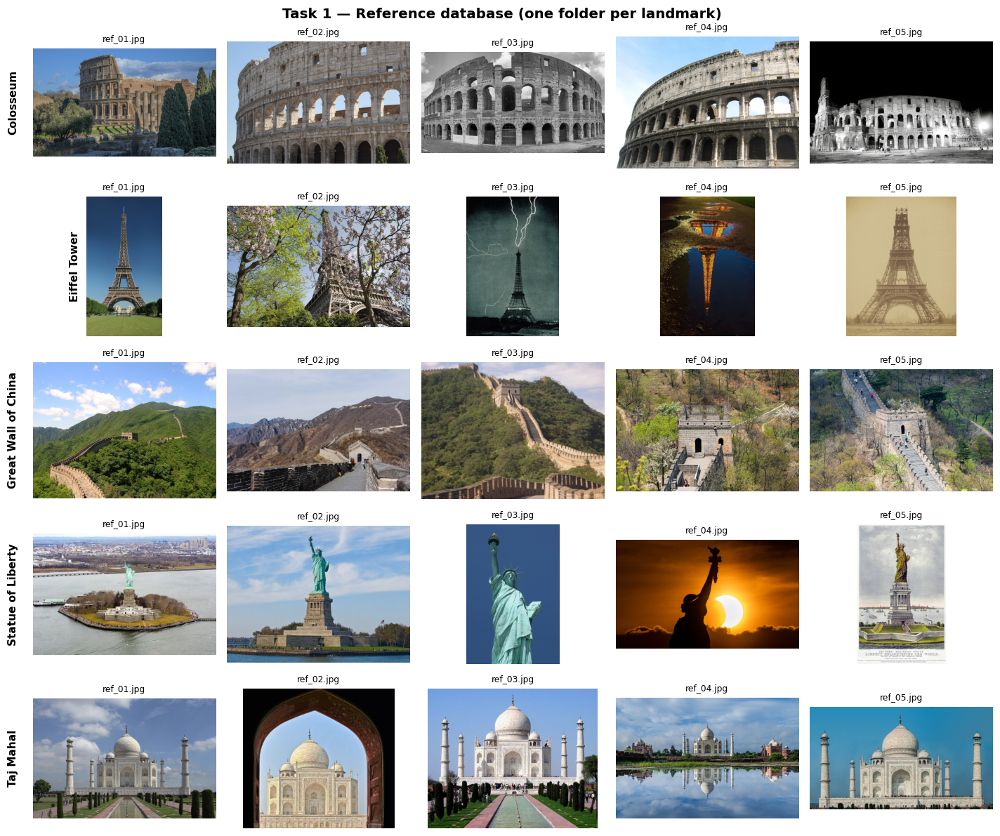

In [5]:
def load_image(path, max_dim: int = MAX_IMAGE_DIM) -> np.ndarray:
    '''Read a colour image and downscale it so that its longest side is at most max_dim (never upscales).'''
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f'Cannot read image: {path}')
    scale = max_dim / max(img.shape[:2])
    if scale < 1.0:
        img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    return img

def rgb(img_bgr: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def nice(name: str) -> str:
    return name.replace('_', ' ')

def savefig(fig, name: str):
    fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight', facecolor='white')

# Contact sheet of the database: one row per landmark
n_cols = max(len(list_images(DB_DIR / lm)) for lm in LANDMARKS)
fig, axes = plt.subplots(len(LANDMARKS), n_cols, figsize=(2.6 * n_cols, 2.2 * len(LANDMARKS)), squeeze=False)
for r, lm in enumerate(LANDMARKS):
    paths = list_images(DB_DIR / lm)
    for c in range(n_cols):
        ax = axes[r, c]; ax.axis('off')
        if c < len(paths):
            ax.imshow(rgb(load_image(paths[c], 400)))
            ax.set_title(paths[c].name, fontsize=8, fontweight='normal')
    axes[r, 0].text(-0.08, 0.5, nice(lm), transform=axes[r, 0].transAxes, rotation=90,
                    ha='right', va='center', fontsize=10, fontweight='bold')
fig.suptitle('Task 1 — Reference database (one folder per landmark)', fontsize=13, fontweight='bold')
fig.tight_layout(); savefig(fig, 'task1_database_contact_sheet'); plt.show()

## 6. SIFT Feature Extraction — *Task 2*



In [6]:
SIFT = cv2.SIFT_create(nfeatures=SIFT_N_FEATURES)

@dataclass
class ReferenceEntry:
    landmark: str
    path: Path
    image: np.ndarray
    keypoints: tuple
    descriptors: np.ndarray

def extract_sift(img_bgr: np.ndarray):
    '''Grayscale conversion + SIFT detection/description. Returns (gray, keypoints, descriptors or None).'''
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = SIFT.detectAndCompute(gray, None)
    return gray, keypoints, descriptors

reference_db = []
t0 = time.perf_counter()
for lm in LANDMARKS:
    for path in list_images(DB_DIR / lm):
        img = load_image(path)
        _, kps, desc = extract_sift(img)
        if desc is None or len(kps) < MIN_HOMOGRAPHY_MATCHES:
            warnings.warn(f'{path} yields only {len(kps)} keypoints and is skipped.'); continue
        assert desc.shape == (len(kps), 128) and desc.dtype == np.float32
        reference_db.append(ReferenceEntry(lm, path, img, kps, desc))
build_time = time.perf_counter() - t0

db_summary = (pd.DataFrame([{'Landmark': nice(e.landmark), 'Keypoints': len(e.keypoints)} for e in reference_db])
              .groupby('Landmark')['Keypoints'].agg(['count', 'sum', 'mean', 'min', 'max']).round(0).astype(int)
              .rename(columns={'count': 'Images', 'sum': 'Total descriptors', 'mean': 'Mean / image',
                               'min': 'Min', 'max': 'Max'}))
display(db_summary)
print(f'{len(reference_db)} reference images encoded in {build_time:.2f} s')

,Images,Total descriptors,Mean / image,Min,Max
Landmark,,,,,
Colosseum,5,10002,2000,2000,2001
Eiffel Tower,5,7760,1552,1200,2000
Great Wall of China,5,10000,2000,2000,2000
Statue of Liberty,5,6195,1239,261,2000
Taj Mahal,5,8991,1798,1492,2000


25 reference images encoded in 4.70 s


### 6.1 Visualising the detected keypoints


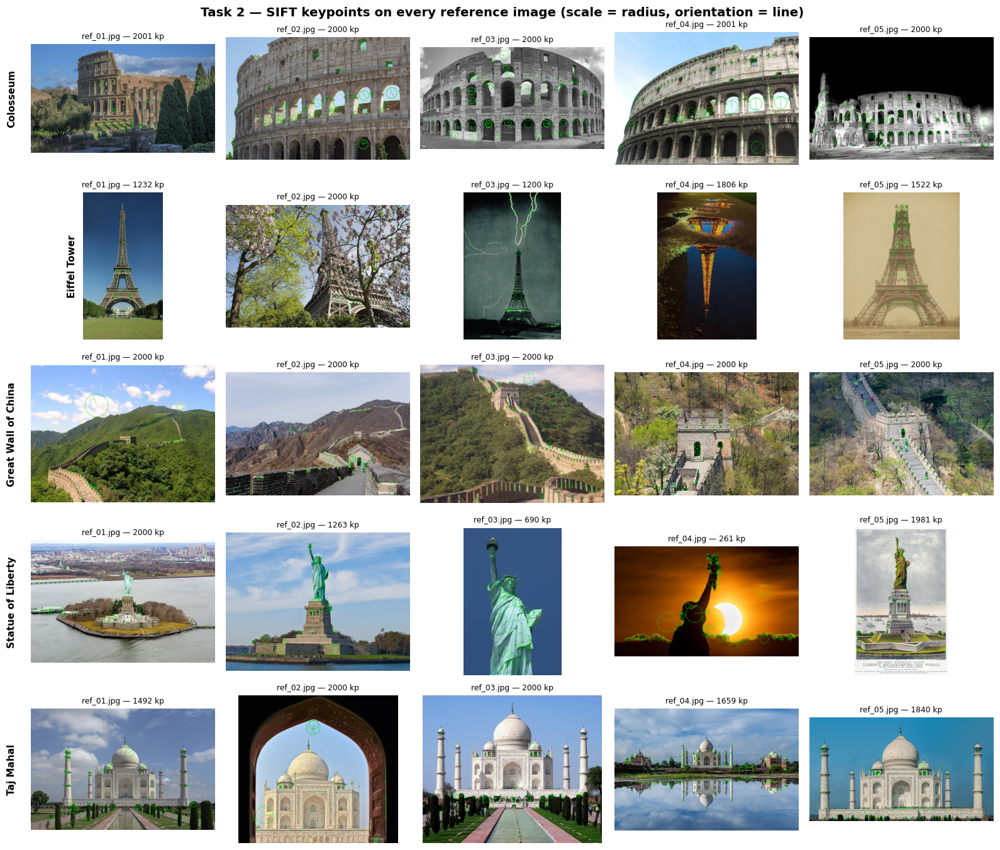

In [7]:
def draw_keypoints(img_bgr, keypoints, max_draw: int = 250, color=(0, 220, 0)) -> np.ndarray:
    strongest = sorted(keypoints, key=lambda k: k.response, reverse=True)[:max_draw]
    return cv2.drawKeypoints(img_bgr, strongest, None, color=color, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

per_lm = {lm: [e for e in reference_db if e.landmark == lm] for lm in LANDMARKS}
n_cols = max(len(v) for v in per_lm.values())
fig, axes = plt.subplots(len(LANDMARKS), n_cols, figsize=(2.9 * n_cols, 2.5 * len(LANDMARKS)), squeeze=False)
for r, lm in enumerate(LANDMARKS):
    for c in range(n_cols):
        ax = axes[r, c]; ax.axis('off')
        if c < len(per_lm[lm]):
            e = per_lm[lm][c]
            ax.imshow(rgb(draw_keypoints(e.image, e.keypoints)))
            ax.set_title(f'{e.path.name} — {len(e.keypoints)} kp', fontsize=8, fontweight='normal')
    axes[r, 0].text(-0.08, 0.5, nice(lm), transform=axes[r, 0].transAxes, rotation=90,
                    ha='right', va='center', fontsize=10, fontweight='bold')
fig.suptitle('Task 2 — SIFT keypoints on every reference image (scale = radius, orientation = line)',
             fontsize=13, fontweight='bold')
fig.tight_layout(); savefig(fig, 'task2_reference_keypoints'); plt.show()

### 6.2 Storing descriptors with their landmark labels
The descriptor database is held in memory (`reference_db`) and also written to disk as a compressed NumPy archive: every descriptor row carries its landmark label and the index of the image it came from, together with the keypoint geometry needed later for homography estimation. This makes the database reusable without recomputing features.

In [8]:
desc_all   = np.vstack([e.descriptors for e in reference_db])
labels_all = np.concatenate([[e.landmark] * len(e.keypoints) for e in reference_db])
img_idx    = np.concatenate([[i] * len(e.keypoints) for i, e in enumerate(reference_db)])
kp_geom    = np.vstack([[(k.pt[0], k.pt[1], k.size, k.angle, k.response) for k in e.keypoints] for e in reference_db])
np.savez_compressed(OUT_DIR / 'sift_descriptor_database.npz', descriptors=desc_all, labels=labels_all,
                    image_index=img_idx, keypoint_xy_size_angle_response=kp_geom,
                    image_paths=np.array([str(e.path) for e in reference_db]))

assert desc_all.shape == (len(labels_all), 128)
chk = np.load(OUT_DIR / 'sift_descriptor_database.npz')
assert np.array_equal(chk['descriptors'], desc_all) and set(chk['labels']) == set(LANDMARKS)
print(f'Stored {desc_all.shape[0]:,} descriptors x {desc_all.shape[1]} dims '
      f'({desc_all.nbytes / 1e6:.1f} MB) for {len(set(labels_all))} landmarks -> outputs/sift_descriptor_database.npz')

Stored 42,948 descriptors x 128 dims (22.0 MB) for 5 landmarks -> outputs/sift_descriptor_database.npz


## 7. Query Image Processing — *Task 3*



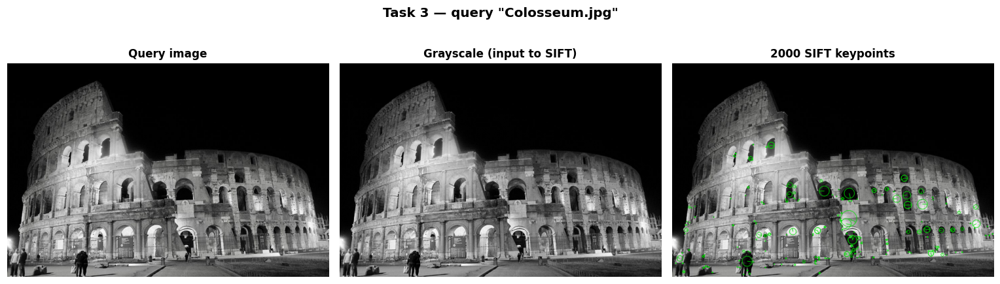

In [9]:
@dataclass
class QueryFeatures:
    image: np.ndarray
    gray: np.ndarray
    keypoints: tuple
    descriptors: Optional[np.ndarray]

def process_query(query) -> QueryFeatures:
    '''Task 3: load (path or BGR array) -> grayscale -> SIFT keypoints -> descriptors.'''
    img = load_image(query) if isinstance(query, (str, Path)) else query
    if img is None or img.ndim != 3:
        raise ValueError('Query must be a path or a BGR colour image array.')
    gray, kps, desc = extract_sift(img)
    return QueryFeatures(img, gray, kps, desc)

def show_query(qf: QueryFeatures, title: str = 'Query', save_as: Optional[str] = None):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
    axes[0].imshow(rgb(qf.image)); axes[0].set_title('Query image')
    axes[1].imshow(qf.gray, cmap='gray'); axes[1].set_title('Grayscale (input to SIFT)')
    axes[2].imshow(rgb(draw_keypoints(qf.image, qf.keypoints))); axes[2].set_title(f'{len(qf.keypoints)} SIFT keypoints')
    for a in axes: a.axis('off')
    fig.suptitle(f'Task 3 — {title}', fontsize=13, fontweight='bold'); fig.tight_layout()
    if save_as: savefig(fig, save_as)
    plt.show()

DEMO_QUERY = next(iter(list_images(HOLDOUT_DIR)), None) or list_images(DB_DIR / LANDMARKS[0])[0]
demo_qf = process_query(DEMO_QUERY)
show_query(demo_qf, f'query "{Path(DEMO_QUERY).name}"', save_as='task3_query_keypoints')

**Optional — test your own photo.** Run the cell below in Colab, upload any landmark photograph, and the full pipeline of Sections 8–10 will be applied to it (run those sections first).

In [10]:
RUN_UPLOAD = False   # set to True to upload your own query photo
if RUN_UPLOAD and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    for fname, data in uploaded.items():
        user_img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
        cv2.imwrite(str(DATA_ROOT / fname), user_img)
        res = recognize(load_image(DATA_ROOT / fname))
        show_result(res, title=f'uploaded "{fname}"', save_as=f'upload_{Path(fname).stem}')

## 8. Feature Matching and Landmark Recognition — *Task 4*

#

In [11]:
BF_MATCHER = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

def ratio_test_matches(desc_query, desc_ref, ratio: float = LOWE_RATIO) -> list:
    '''k-NN (k=2) Euclidean matching followed by Lowe's ratio test.
    Returned DMatch objects: queryIdx -> query keypoint, trainIdx -> reference keypoint.'''
    if desc_query is None or desc_ref is None or len(desc_query) < 2 or len(desc_ref) < 2:
        return []
    good = []
    for pair in BF_MATCHER.knnMatch(desc_query, desc_ref, k=2):
        if len(pair) < 2:
            continue
        best, second = pair
        if best.distance < ratio * second.distance:
            good.append(best)
    return good

@dataclass
class Candidate:
    landmark: str
    good_matches: int                  # reliable matches with the best reference image
    best_ref: ReferenceEntry
    matches: list                      # DMatch list for best_ref
    per_reference: list                # reliable matches with every reference image of this landmark
    inliers: int = 0
    geometry: Optional[dict] = None

def rank_landmarks(qf: QueryFeatures) -> list:
    '''Task 4.1-4.5: match against every reference image and rank landmarks by reliable matches.'''
    by_landmark = {}
    for entry in reference_db:
        m = ratio_test_matches(qf.descriptors, entry.descriptors)
        by_landmark.setdefault(entry.landmark, []).append((len(m), entry, m))
    ranking = []
    for lm, lst in by_landmark.items():
        n, entry, m = max(lst, key=lambda t: t[0])
        ranking.append(Candidate(lm, n, entry, m, [t[0] for t in lst]))
    return sorted(ranking, key=lambda c: c.good_matches, reverse=True)

ranking_demo = rank_landmarks(demo_qf)
display(pd.DataFrame([{'Rank': i + 1, 'Landmark': nice(c.landmark), 'Reliable matches (best reference)': c.good_matches,
                       'Best reference': c.best_ref.path.name, 'Matches per reference': c.per_reference}
                      for i, c in enumerate(ranking_demo)]).style.hide(axis='index'))

Rank,Landmark,Reliable matches (best reference),Best reference,Matches per reference
1,Colosseum,45,ref_05.jpg,"[10, 14, 5, 8, 45]"
2,Eiffel Tower,21,ref_01.jpg,"[21, 11, 11, 10, 13]"
3,Great Wall of China,18,ref_02.jpg,"[8, 18, 14, 12, 12]"
4,Taj Mahal,18,ref_01.jpg,"[18, 10, 7, 17, 8]"
5,Statue of Liberty,17,ref_02.jpg,"[14, 17, 13, 17, 7]"


## 9. Landmark Localization — *Task 5*



In [12]:
def homography_is_plausible(H: np.ndarray, polygon: np.ndarray, query_shape) -> tuple:
    qh, qw = query_shape[:2]
    det = float(np.linalg.det(H[:2, :2]))
    if not (0.01 < det < 100):
        return False, f'degenerate transformation (det of linear part = {det:.3g})'
    poly = polygon.reshape(-1, 2).astype(np.float32)
    if not cv2.isContourConvex(poly):
        return False, 'projected region is not convex (folded / twisted)'
    area_frac = cv2.contourArea(poly) / float(qw * qh)
    if area_frac < 0.01:
        return False, f'projected region too small ({area_frac:.2%} of the image)'
    margin = 1.0
    if (poly[:, 0].min() < -margin * qw or poly[:, 0].max() > (1 + margin) * qw or
            poly[:, 1].min() < -margin * qh or poly[:, 1].max() > (1 + margin) * qh):
        return False, 'projected corners lie far outside the query image'
    return True, 'ok'

def localize(qf: QueryFeatures, cand: Candidate) -> dict:
    '''Task 5: RANSAC homography from reference -> query and projection of the reference corners.'''
    result = {'H': None, 'mask': None, 'inliers': 0, 'polygon': None, 'valid': False, 'reason': ''}
    if len(cand.matches) < MIN_HOMOGRAPHY_MATCHES:
        result['reason'] = f'only {len(cand.matches)} reliable matches (< {MIN_HOMOGRAPHY_MATCHES}); homography not attempted'
        return result
    src = np.float32([cand.best_ref.keypoints[m.trainIdx].pt for m in cand.matches]).reshape(-1, 1, 2)
    dst = np.float32([qf.keypoints[m.queryIdx].pt for m in cand.matches]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_REPROJ_THRESHOLD)
    if H is None or mask is None:
        result['reason'] = 'RANSAC could not find a homography'
        return result
    result.update(H=H, mask=mask.ravel().astype(bool), inliers=int(mask.sum()))
    h, w = cand.best_ref.image.shape[:2]
    corners = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]]).reshape(-1, 1, 2)
    polygon = cv2.perspectiveTransform(corners, H)
    result['polygon'] = polygon
    if result['inliers'] < MIN_INLIERS:
        result['reason'] = f"only {result['inliers']} RANSAC inliers (< {MIN_INLIERS})"
        return result
    result['valid'], result['reason'] = homography_is_plausible(H, polygon, qf.image.shape)
    return result

### 9.1 The complete recogniser


In [13]:
@dataclass
class RecognitionResult:
    query: QueryFeatures
    ranking: list
    prediction: Optional[Candidate]       # best verified candidate (may still be rejected)
    recognized: bool
    reason: str
    seconds: float

    @property
    def label(self) -> str:
        return self.prediction.landmark if (self.recognized and self.prediction) else 'REJECTED'

def recognize(query) -> RecognitionResult:
    t0 = time.perf_counter()
    qf = process_query(query)
    if qf.descriptors is None or len(qf.keypoints) < MIN_HOMOGRAPHY_MATCHES:
        return RecognitionResult(qf, [], None, False, 'too few keypoints in the query', time.perf_counter() - t0)
    ranking = rank_landmarks(qf)
    for cand in ranking[:TOP_K_VERIFY]:
        cand.geometry = localize(qf, cand)
        cand.inliers = cand.geometry['inliers']
    best = max(ranking[:TOP_K_VERIFY], key=lambda c: (c.inliers, c.good_matches))
    ok_matches = best.good_matches >= MIN_GOOD_MATCHES
    ok_inliers = best.inliers >= MIN_INLIERS
    recognized = ok_matches and ok_inliers
    if recognized:
        reason = f'{best.good_matches} reliable matches >= {MIN_GOOD_MATCHES} and {best.inliers} inliers >= {MIN_INLIERS}'
    else:
        failed = []
        if not ok_matches: failed.append(f'{best.good_matches} reliable matches < {MIN_GOOD_MATCHES}')
        if not ok_inliers: failed.append(f'{best.inliers} inliers < {MIN_INLIERS}')
        reason = 'insufficient evidence: ' + '; '.join(failed)
    return RecognitionResult(qf, ranking, best, recognized, reason, time.perf_counter() - t0)

### 9.2 Result display


In [14]:
def draw_match_panel(qf: QueryFeatures, cand: Candidate, max_lines: int = 60) -> np.ndarray:
    '''Side-by-side query | reference; inliers green, outliers red (subsampled for legibility).'''
    mask = cand.geometry['mask'] if cand.geometry and cand.geometry['mask'] is not None else np.zeros(len(cand.matches), bool)
    rng = np.random.default_rng(SEED)
    inl = [m for m, k in zip(cand.matches, mask) if k]
    out = [m for m, k in zip(cand.matches, mask) if not k]
    inl = list(rng.choice(inl, min(len(inl), max_lines), replace=False)) if inl else []
    out = list(rng.choice(out, min(len(out), max_lines // 3), replace=False)) if out else []
    canvas = cv2.drawMatches(qf.image, qf.keypoints, cand.best_ref.image, cand.best_ref.keypoints, out, None,
                             matchColor=(60, 60, 220), singlePointColor=None,
                             flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)
    canvas = cv2.drawMatches(qf.image, qf.keypoints, cand.best_ref.image, cand.best_ref.keypoints, inl, canvas,
                             matchColor=(40, 200, 40), singlePointColor=None,
                             flags=cv2.DRAW_MATCHES_FLAGS_DRAW_OVER_OUTIMG | cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)
    return canvas

def draw_localization(qf: QueryFeatures, cand: Optional[Candidate]) -> tuple:
    img = qf.image.copy()
    geo = cand.geometry if cand else None
    if geo and geo['valid']:
        thick = max(2, int(round(max(img.shape[:2]) / 200)))
        cv2.polylines(img, [np.int32(geo['polygon'])], True, (0, 0, 230), thick, cv2.LINE_AA)
        return img, 'Landmark region localized'
    return img, 'Localization unreliable — polygon not drawn' + (f"\n({geo['reason']})" if geo else '')

def show_result(res: RecognitionResult, title: str = '', save_as: Optional[str] = None,
                ground_truth: Optional[str] = None, show: bool = True):
    qf, cand = res.query, res.prediction
    fig = plt.figure(figsize=(16, 9.2))
    gs = gridspec.GridSpec(2, 3, figure=fig, height_ratios=[1, 1.05], hspace=0.28, wspace=0.12)
    ax0 = fig.add_subplot(gs[0, 0]); ax0.imshow(rgb(qf.image)); ax0.set_title('(1) Query image'); ax0.axis('off')
    ax1 = fig.add_subplot(gs[0, 1]); ax1.imshow(rgb(draw_keypoints(qf.image, qf.keypoints)))
    ax1.set_title(f'(2) SIFT keypoints: {len(qf.keypoints)}'); ax1.axis('off')

    ax2 = fig.add_subplot(gs[0, 2])
    if res.ranking:
        names = [nice(c.landmark) for c in res.ranking][::-1]
        vals = [c.good_matches for c in res.ranking][::-1]
        cols = [LANDMARK_COLORS[c.landmark] if (cand and c.landmark == cand.landmark) else '#c9c8c2' for c in res.ranking][::-1]
        bars = ax2.barh(names, vals, color=cols, height=0.62, edgecolor='white', linewidth=2)
        ax2.axvline(MIN_GOOD_MATCHES, color='#52514e', ls='--', lw=1)
        ax2.text(MIN_GOOD_MATCHES, 1.01, f'T_m = {MIN_GOOD_MATCHES}', transform=ax2.get_xaxis_transform(),
                 fontsize=8, color='#52514e', ha='center', va='bottom')
        for b, v in zip(bars, vals):
            ax2.text(b.get_width(), b.get_y() + b.get_height() / 2, f' {v}', va='center', fontsize=9)
        ax2.set_xlabel('Reliable matches (best reference image)')
        ax2.set_xlim(0, max(max(vals), MIN_GOOD_MATCHES) * 1.18)
    ax2.set_title('(4–5) Landmark ranking', pad=16)

    ax3 = fig.add_subplot(gs[1, 0:2])
    if cand is not None:
        ax3.imshow(rgb(draw_match_panel(qf, cand)))
        ax3.set_title(f'(3) Matches: query (left) vs best reference "{cand.best_ref.path.name}" of {nice(cand.landmark)} '
                      f'— green = RANSAC inliers, red = outliers (subsampled)', fontsize=10)
    ax3.axis('off')

    ax4 = fig.add_subplot(gs[1, 2])
    loc_img, loc_msg = draw_localization(qf, cand)
    ax4.imshow(rgb(loc_img)); ax4.set_title(f'(6) {loc_msg}', fontsize=9.5); ax4.axis('off')

    status = 'RECOGNIZED' if res.recognized else 'REJECTED'
    colr = ACCEPT_COLOR if res.recognized else REJECT_COLOR
    pred = nice(cand.landmark) if (res.recognized and cand) else 'none (unknown / insufficient evidence)'
    lines = [f'Predicted landmark : {pred}',
             f'Reliable matches   : {cand.good_matches if cand else 0}',
             f'RANSAC inliers     : {cand.inliers if cand else 0}',
             f'Processing time    : {res.seconds:.3f} s']
    if ground_truth: lines.insert(0, f'Ground truth       : {nice(ground_truth)}')
    fig.text(0.5, 0.965, f'(7) {status}' + (f' — {title}' if title else ''), ha='center', fontsize=14,
             fontweight='bold', color=colr)
    fig.text(0.5, 0.925, '   |   '.join(lines) + f'\nDecision: {res.reason}', ha='center', va='top',
             fontsize=9.5, family='monospace', color='#0b0b0b')
    fig.subplots_adjust(top=0.86)
    if save_as: savefig(fig, save_as)
    if show:
        plt.show()
    else:
        plt.close(fig)

## 10. End-to-End Demonstration

The full pipeline applied to the demonstration query from Section 7 (a held-out photograph that is **not** in the database).

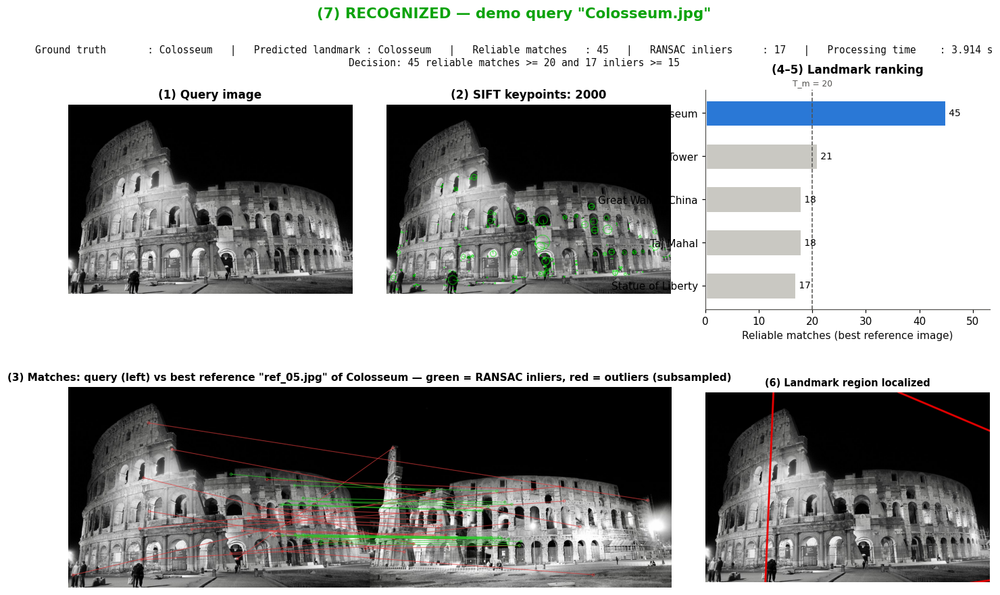

Rank,Landmark,Reliable matches,RANSAC inliers,Geometry
1,Colosseum,45,17,ok
2,Eiffel Tower,21,6,only 6 RANSAC inliers (< 15)
3,Great Wall of China,18,6,only 6 RANSAC inliers (< 15)
4,Taj Mahal,18,— (not verified),—
5,Statue of Liberty,17,— (not verified),—


In [15]:
demo_truth = Path(DEMO_QUERY).stem if Path(DEMO_QUERY).parent == HOLDOUT_DIR else Path(DEMO_QUERY).parent.name
demo_res = recognize(DEMO_QUERY)
show_result(demo_res, title=f'demo query "{Path(DEMO_QUERY).name}"', save_as='task4_5_demo_result', ground_truth=demo_truth)

display(pd.DataFrame([{'Rank': i + 1, 'Landmark': nice(c.landmark), 'Reliable matches': c.good_matches,
                       'RANSAC inliers': c.inliers if i < TOP_K_VERIFY else '— (not verified)',
                       'Geometry': (c.geometry['reason'] if c.geometry else '—')}
                      for i, c in enumerate(demo_res.ranking)]).style.hide(axis='index'))

## 11. Performance Evaluation — *Task 6*



32 test queries: {'Original': 5, 'Rotated': 5, 'Resized': 5, 'Low brightness': 5, 'Viewpoint (synthetic)': 5, 'Viewpoint (real photo)': 5, 'Unknown landmark': 2}


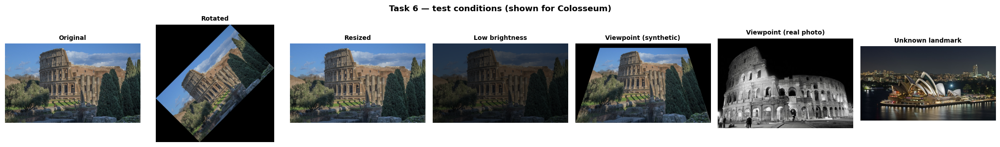

In [16]:
def rotate_image(img, angle_deg):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle_deg, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0))

def resize_image(img, factor):
    return cv2.resize(img, None, fx=factor, fy=factor, interpolation=cv2.INTER_AREA)

def darken_image(img, factor):
    return cv2.convertScaleAbs(img, alpha=factor, beta=0)

def perspective_image(img, shift):
    h, w = img.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = np.float32([[shift * w, 0.06 * h], [(1 - shift) * w, 0.06 * h], [w, h], [0, h]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (w, h), borderValue=(0, 0, 0))

CONDITIONS = ['Original', 'Rotated', 'Resized', 'Low brightness', 'Viewpoint (synthetic)',
              'Viewpoint (real photo)', 'Unknown landmark']

def build_test_suite() -> list:
    tests = []
    for lm in LANDMARKS:
        base_path = list_images(DB_DIR / lm)[0]
        base = load_image(base_path)
        tests += [
            ('Original', lm, base, base_path.name),
            ('Rotated', lm, rotate_image(base, ROTATION_DEG), f'{base_path.name} rotated {ROTATION_DEG} deg'),
            ('Resized', lm, resize_image(base, RESIZE_FACTOR), f'{base_path.name} x{RESIZE_FACTOR}'),
            ('Low brightness', lm, darken_image(base, BRIGHTNESS_FACTOR), f'{base_path.name} intensity x{BRIGHTNESS_FACTOR}'),
            ('Viewpoint (synthetic)', lm, perspective_image(base, PERSPECTIVE_SHIFT), f'{base_path.name} perspective warp'),
        ]
        hold = [p for p in list_images(HOLDOUT_DIR) if p.stem == lm]
        if hold:
            tests.append(('Viewpoint (real photo)', lm, load_image(hold[0]), f'holdout/{hold[0].name}'))
    for p in list_images(UNKNOWN_DIR):
        tests.append(('Unknown landmark', 'Unknown', load_image(p), f'unknown/{p.name}'))
    return tests

test_suite = build_test_suite()
print(f'{len(test_suite)} test queries:', pd.Series([t[0] for t in test_suite]).value_counts().reindex(CONDITIONS).to_dict())

# Preview of the six conditions for the first landmark
preview = [t for t in test_suite if t[1] == LANDMARKS[0]] + [t for t in test_suite if t[0] == 'Unknown landmark'][:1]
fig, axes = plt.subplots(1, len(preview), figsize=(2.9 * len(preview), 3))
for ax, (cond, gt, img, desc) in zip(np.atleast_1d(axes), preview):
    ax.imshow(rgb(img)); ax.set_title(cond, fontsize=9); ax.axis('off')
fig.suptitle(f'Task 6 — test conditions (shown for {nice(LANDMARKS[0])})', fontsize=12, fontweight='bold')
fig.tight_layout(); savefig(fig, 'task6_test_conditions'); plt.show()

### 11.1 Running the experiment


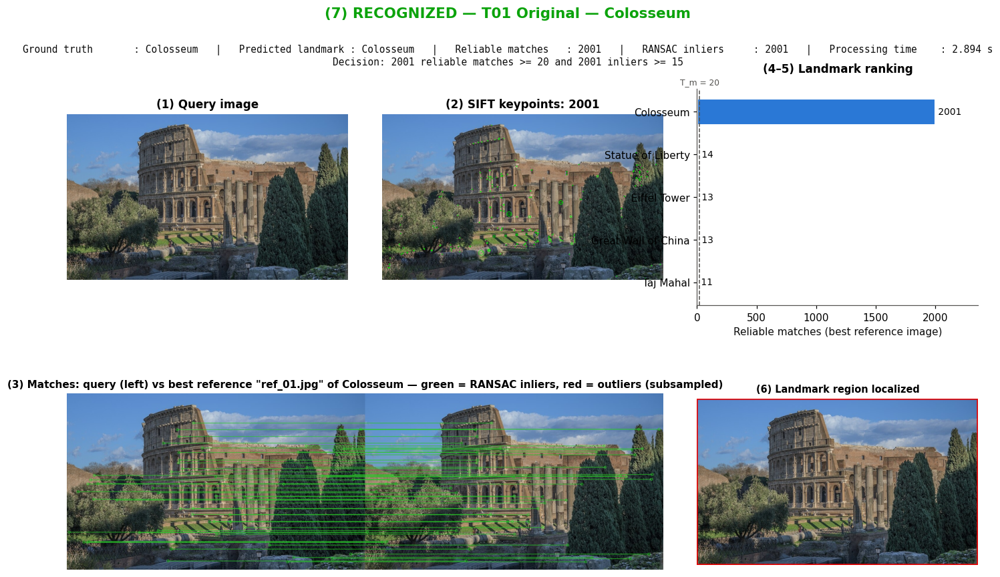

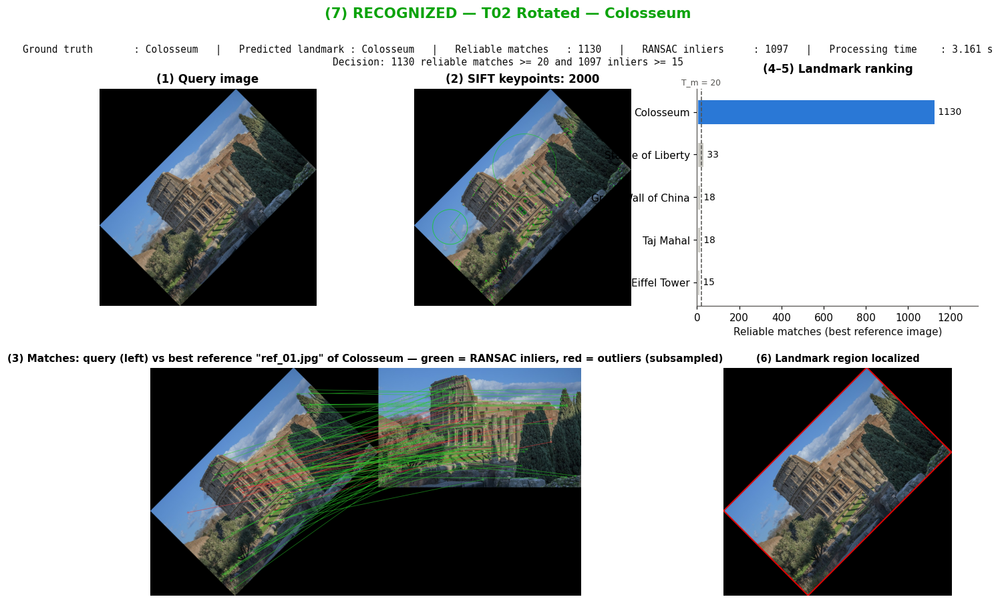

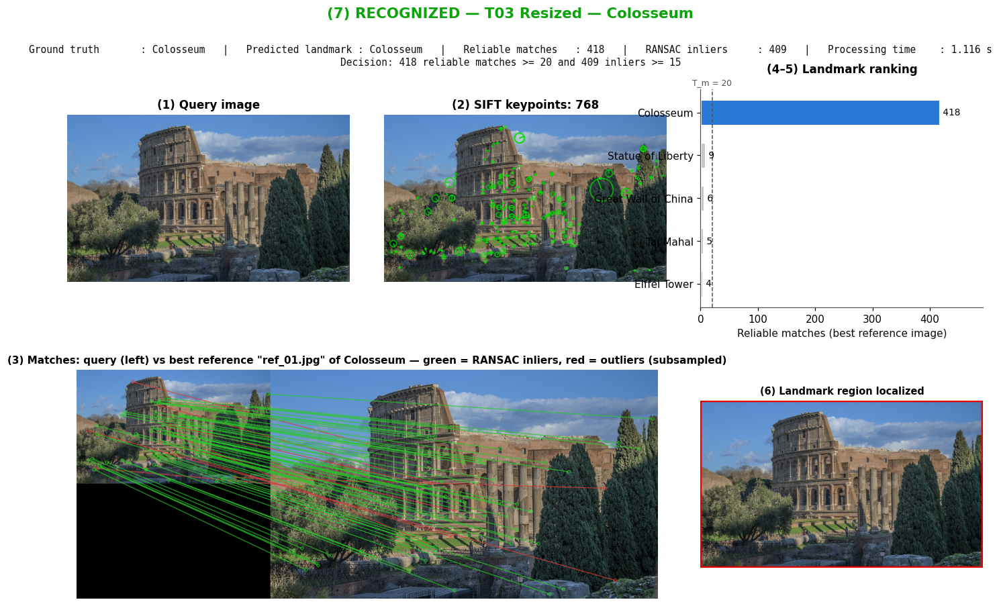

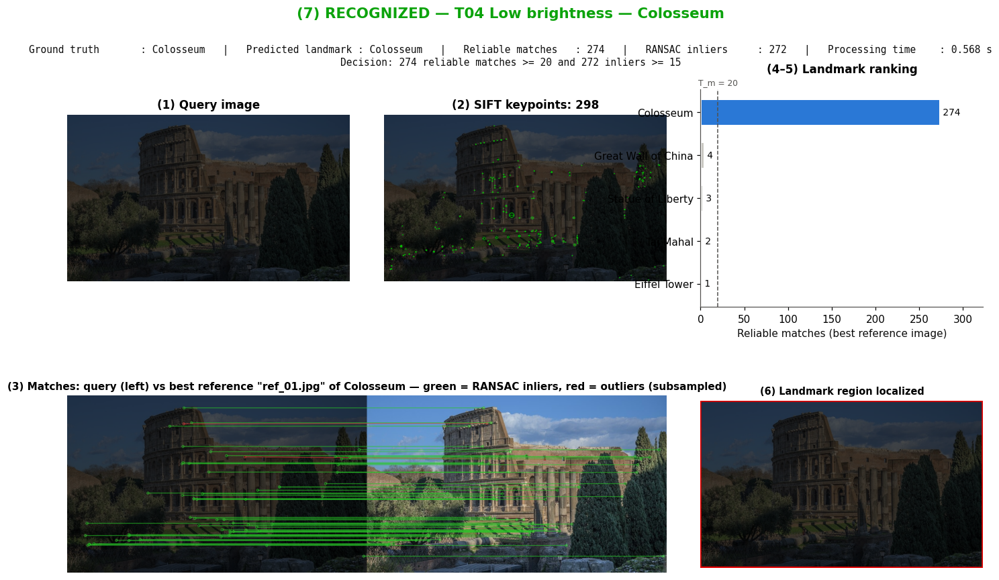

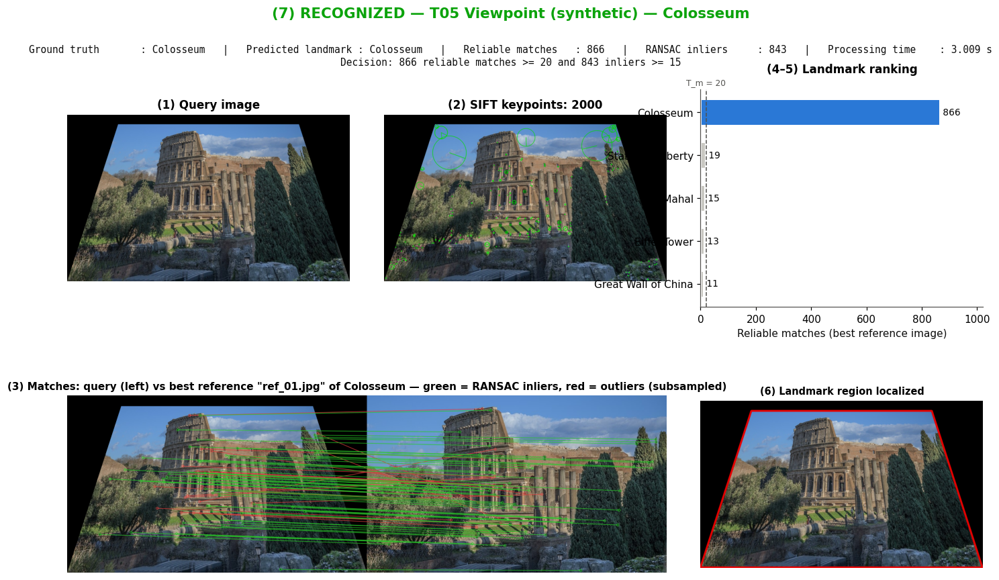

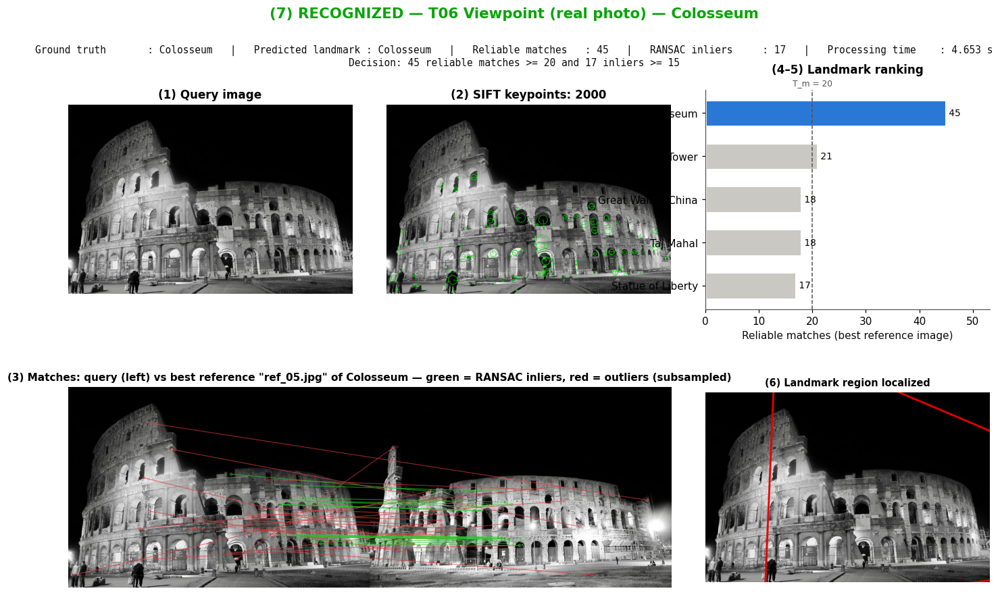

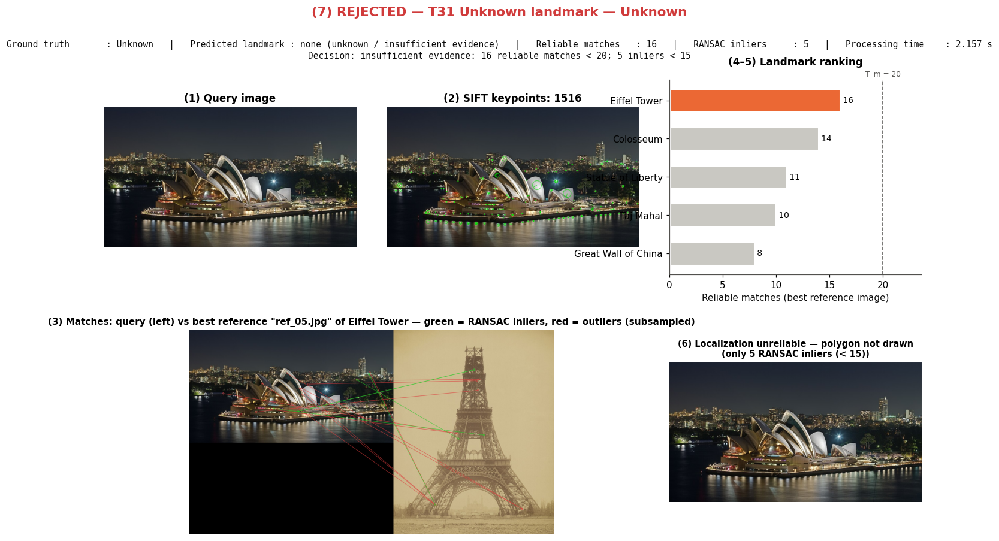

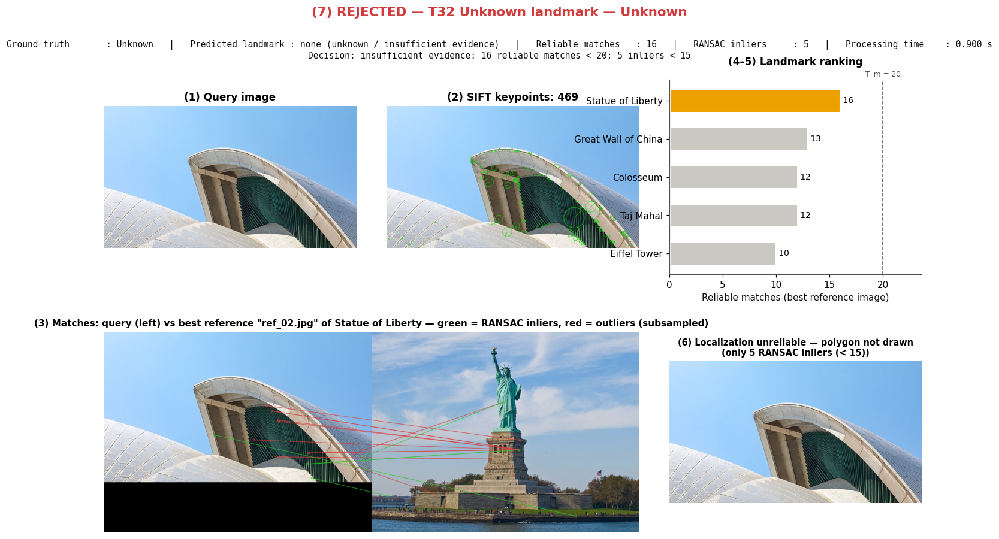

Saved 32 rows -> outputs/experimental_results.csv; 33 screenshots -> outputs/screenshots/


In [17]:
SHOW_INLINE_FOR = LANDMARKS[0]
records, results = [], []
for i, (cond, gt, img, desc) in enumerate(test_suite, start=1):
    res = recognize(img)
    results.append(res)
    known = gt != 'Unknown'
    correct = (res.recognized and res.label == gt) if known else (not res.recognized)
    cand = res.prediction
    records.append({
        'Test': f'T{i:02d}', 'Condition': cond, 'Ground truth': nice(gt), 'Query': desc,
        'Top-ranked landmark': nice(res.ranking[0].landmark) if res.ranking else '—',
        'Predicted landmark': nice(res.label) if res.recognized else 'REJECTED',
        'Keypoints': len(res.query.keypoints),
        'Reliable matches': cand.good_matches if cand else 0,
        'RANSAC inliers': cand.inliers if cand else 0,
        'Localization': 'polygon' if (cand and cand.geometry and cand.geometry['valid']) else 'unreliable',
        'Decision': 'Recognized' if res.recognized else 'Rejected',
        'Correct': correct,
        'Time (s)': round(res.seconds, 3),
    })
    fname = f'task6_T{i:02d}_{gt}_{cond}'.replace(' ', '_').replace('(', '').replace(')', '')
    show_result(res, title=f'T{i:02d} {cond} — {nice(gt)}', save_as=fname, ground_truth=gt,
                show=(gt == SHOW_INLINE_FOR or not known))

results_df = pd.DataFrame(records)
results_df.to_csv(OUT_DIR / 'experimental_results.csv', index=False)
print('Saved', len(results_df), 'rows -> outputs/experimental_results.csv;',
      len(list(FIG_DIR.glob('task6_*.png'))), 'screenshots -> outputs/screenshots/')

### 11.2 Table of experimental results

In [18]:
def _style_row(row):
    c = '#e8f5e8' if row['Correct'] else '#fbe9e9'
    return [f'background-color: {c}' if col in ('Decision', 'Correct') else '' for col in row.index]

display(results_df.drop(columns=['Query']).style.apply(_style_row, axis=1).hide(axis='index')
        .format({'Time (s)': '{:.3f}'}).set_caption('Per-test results (green = correct decision, red = error)'))

Test,Condition,Ground truth,Top-ranked landmark,Predicted landmark,Keypoints,Reliable matches,RANSAC inliers,Localization,Decision,Correct,Time (s)
T01,Original,Colosseum,Colosseum,Colosseum,2001,2001,2001,polygon,Recognized,True,2.894
T02,Rotated,Colosseum,Colosseum,Colosseum,2000,1130,1097,polygon,Recognized,True,3.161
T03,Resized,Colosseum,Colosseum,Colosseum,768,418,409,polygon,Recognized,True,1.116
T04,Low brightness,Colosseum,Colosseum,Colosseum,298,274,272,polygon,Recognized,True,0.568
T05,Viewpoint (synthetic),Colosseum,Colosseum,Colosseum,2000,866,843,polygon,Recognized,True,3.009
T06,Viewpoint (real photo),Colosseum,Colosseum,Colosseum,2000,45,17,polygon,Recognized,True,4.653
T07,Original,Eiffel Tower,Eiffel Tower,Eiffel Tower,1232,1232,1232,polygon,Recognized,True,1.848
T08,Rotated,Eiffel Tower,Eiffel Tower,Eiffel Tower,1743,918,860,polygon,Recognized,True,2.676
T09,Resized,Eiffel Tower,Eiffel Tower,Eiffel Tower,290,198,198,polygon,Recognized,True,0.408
T10,Low brightness,Eiffel Tower,Eiffel Tower,Eiffel Tower,557,516,511,polygon,Recognized,True,0.828


## 12. Visualization and Analysis



In [19]:
summary = (results_df.groupby('Condition', sort=False)
           .agg(Tests=('Test', 'count'), Correct=('Correct', 'sum'),
                **{'Mean keypoints': ('Keypoints', 'mean'), 'Mean reliable matches': ('Reliable matches', 'mean'),
                   'Mean inliers': ('RANSAC inliers', 'mean'), 'Mean time (s)': ('Time (s)', 'mean')})
           .reindex([c for c in CONDITIONS if c in set(results_df['Condition'])]))
summary.insert(2, 'Accuracy', summary['Correct'] / summary['Tests'])
display(summary.style.format({'Accuracy': '{:.0%}', 'Mean keypoints': '{:.0f}', 'Mean reliable matches': '{:.1f}',
                              'Mean inliers': '{:.1f}', 'Mean time (s)': '{:.3f}'})
        .set_caption('Results aggregated per test condition'))

known = results_df[results_df['Ground truth'] != 'Unknown']
unknown = results_df[results_df['Ground truth'] == 'Unknown']
false_reject = int((known['Decision'] == 'Rejected').sum())
confusions = int(((known['Decision'] == 'Recognized') & ~known['Correct']).sum())
false_accept_unknown = int((unknown['Decision'] == 'Recognized').sum())
metrics = pd.DataFrame({'Value': [
    f"{known['Correct'].mean():.1%}  ({known['Correct'].sum()}/{len(known)})",
    f"{false_reject}/{len(known)}",
    f"{confusions}/{len(known)}",
    f"{(unknown['Decision'] == 'Rejected').mean():.0%}  ({(unknown['Decision'] == 'Rejected').sum()}/{len(unknown)})" if len(unknown) else 'n/a',
    f"{results_df['Correct'].mean():.1%}  ({results_df['Correct'].sum()}/{len(results_df)})",
    f"{results_df['Time (s)'].median():.3f} s (max {results_df['Time (s)'].max():.3f} s)",
]}, index=['Recognition accuracy on known landmarks', 'False rejections (known landmark rejected)',
           'Confusions (wrong known landmark accepted)', 'Rejection rate on unknown landmark',
           'Overall correct decisions', 'Median processing time per query'])
display(metrics)

,Tests,Correct,Accuracy,Mean keypoints,Mean reliable matches,Mean inliers,Mean time (s)
Condition,,,,,,,
Original,5,5,100%,1745,1745.0,1745.0,2.546
Rotated,5,5,100%,1928,1033.2,998.0,3.571
Resized,5,5,100%,618,346.2,341.8,0.937
Low brightness,5,5,100%,460,426.6,425.0,0.862
Viewpoint (synthetic),5,5,100%,1835,716.6,690.0,2.974
Viewpoint (real photo),5,2,40%,1489,221.2,198.8,3.283
Unknown landmark,2,2,100%,992,16.0,5.0,1.528


,Value
Recognition accuracy on known landmarks,90.0% (27/30)
False rejections (known landmark rejected),3/30
Confusions (wrong known landmark accepted),0/30
Rejection rate on unknown landmark,100% (2/2)
Overall correct decisions,90.6% (29/32)
Median processing time per query,2.655 s (max 4.863 s)


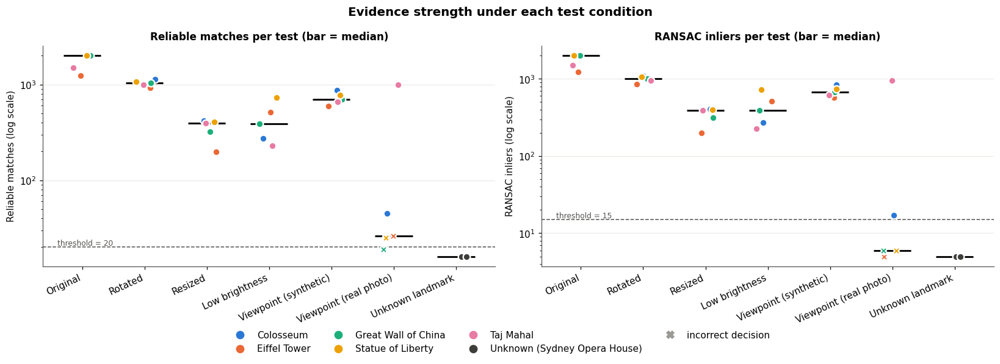

In [20]:
cond_order = list(summary.index)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
rng = np.random.default_rng(SEED)
for ax, metric, thr in [(axes[0], 'Reliable matches', MIN_GOOD_MATCHES), (axes[1], 'RANSAC inliers', MIN_INLIERS)]:
    for x, cond in enumerate(cond_order):
        sub = results_df[results_df['Condition'] == cond]
        for _, row in sub.iterrows():
            gt = row['Ground truth'].replace(' ', '_')
            col = LANDMARK_COLORS.get(gt, '#3d3d3a')
            ax.scatter(x + rng.uniform(-0.18, 0.18), max(row[metric], 0.8), s=58, color=col,
                       edgecolor='white', linewidth=1.5, marker='o' if row['Correct'] else 'X', zorder=3)
        ax.hlines(sub[metric].median(), x - 0.3, x + 0.3, color='#0b0b0b', lw=2, zorder=2)
    ax.axhline(thr, color='#52514e', ls='--', lw=1)
    ax.text(-0.4, thr, f'threshold = {thr}', ha='left', va='bottom', fontsize=8, color='#52514e')
    ax.set_yscale('log'); ax.set_ylabel(f'{metric} (log scale)')
    ax.set_xticks(range(len(cond_order))); ax.set_xticklabels(cond_order, rotation=25, ha='right')
    ax.set_title(f'{metric} per test (bar = median)')
    ax.grid(axis='y', color='#ecebe7', lw=0.8, zorder=0)
handles = [plt.Line2D([], [], marker='o', ls='', color=LANDMARK_COLORS[lm], label=nice(lm), markersize=8) for lm in LANDMARKS]
handles += [plt.Line2D([], [], marker='o', ls='', color='#3d3d3a', label='Unknown (' + ', '.join(nice(k) for k in UNKNOWN_QUERIES) + ')', markersize=8),
            plt.Line2D([], [], marker='X', ls='', color='#9a9993', label='incorrect decision', markersize=8)]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Evidence strength under each test condition', fontsize=13, fontweight='bold')
fig.tight_layout(); savefig(fig, 'analysis_matches_inliers_by_condition'); plt.show()

### 12.3 Keypoint repeatability and processing time

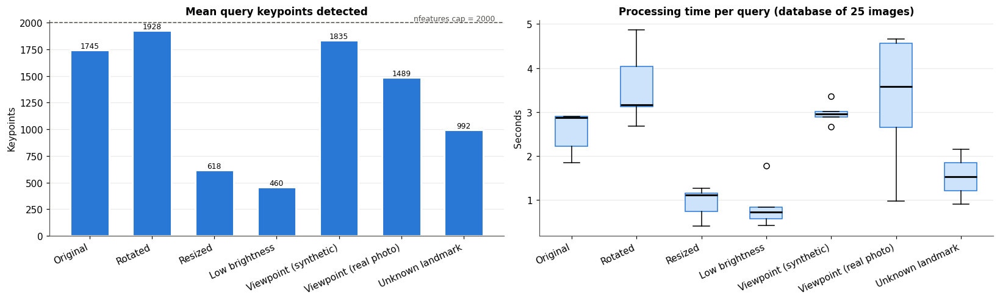

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
k = summary['Mean keypoints']
axes[0].bar(range(len(k)), k.values, color=PALETTE[0], width=0.62, edgecolor='white', linewidth=2)
for x, v in enumerate(k.values):
    axes[0].text(x, v, f'{v:.0f}', ha='center', va='bottom', fontsize=8)
axes[0].axhline(SIFT_N_FEATURES, color='#52514e', ls='--', lw=1)
axes[0].text(len(k) - 0.5, SIFT_N_FEATURES, f'nfeatures cap = {SIFT_N_FEATURES}', ha='right', va='bottom', fontsize=8, color='#52514e')
axes[0].set_title('Mean query keypoints detected'); axes[0].set_ylabel('Keypoints')

t = [results_df.loc[results_df['Condition'] == c, 'Time (s)'].values for c in cond_order]
bp = axes[1].boxplot(t, widths=0.5, patch_artist=True, medianprops=dict(color='#0b0b0b', lw=2))
for b in bp['boxes']:
    b.set_facecolor('#cde2fb'); b.set_edgecolor(PALETTE[0])
axes[1].set_title(f'Processing time per query (database of {len(reference_db)} images)'); axes[1].set_ylabel('Seconds')
axes[0].set_xticks(range(len(cond_order)))
axes[1].set_xticks(range(1, len(cond_order) + 1))   # boxplot positions start at 1
for ax in axes:
    ax.set_xticklabels(cond_order, rotation=25, ha='right'); ax.grid(axis='y', color='#ecebe7', lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); savefig(fig, 'analysis_keypoints_and_time'); plt.show()

### 12.4 Confusion matrix (including the reject option)

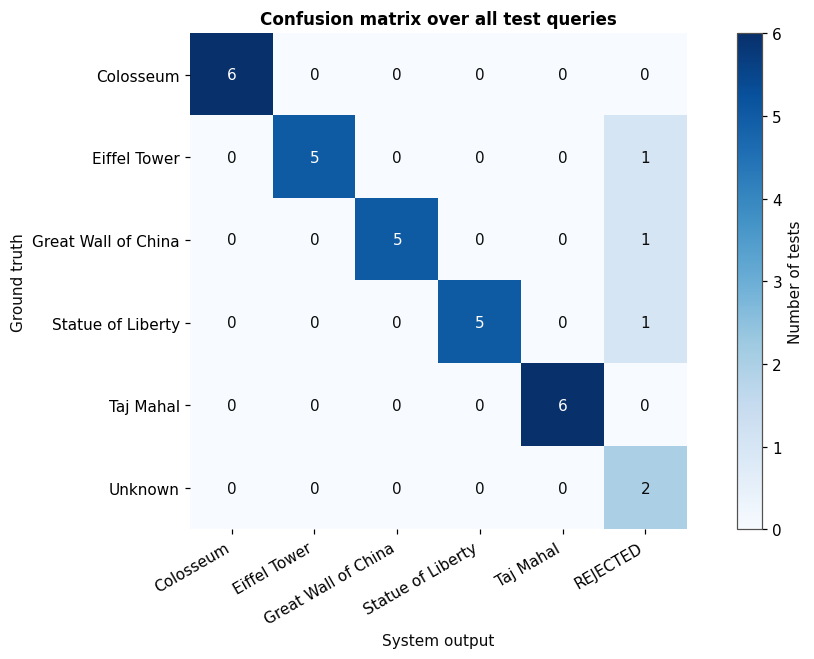

In [22]:
row_labels = [nice(l) for l in LANDMARKS] + (['Unknown'] if len(unknown) else [])
col_labels = [nice(l) for l in LANDMARKS] + ['REJECTED']
cm = pd.crosstab(pd.Categorical(results_df['Ground truth'], categories=row_labels),
                 pd.Categorical(results_df['Predicted landmark'], categories=col_labels), dropna=False)
fig, ax = plt.subplots(figsize=(1.3 * len(col_labels) + 2, 0.75 * len(row_labels) + 1.6))
im = ax.imshow(cm.values, cmap='Blues', vmin=0)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        v = cm.values[i, j]
        ax.text(j, i, str(v), ha='center', va='center', fontsize=10,
                color='white' if v > cm.values.max() * 0.55 else '#0b0b0b')
ax.set_xticks(range(len(col_labels))); ax.set_xticklabels(col_labels, rotation=30, ha='right')
ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels)
ax.set_xlabel('System output'); ax.set_ylabel('Ground truth'); ax.set_title('Confusion matrix over all test queries')
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.03, label='Number of tests')
fig.tight_layout(); savefig(fig, 'analysis_confusion_matrix'); plt.show()

### 12.5 Threshold sensitivity analysis


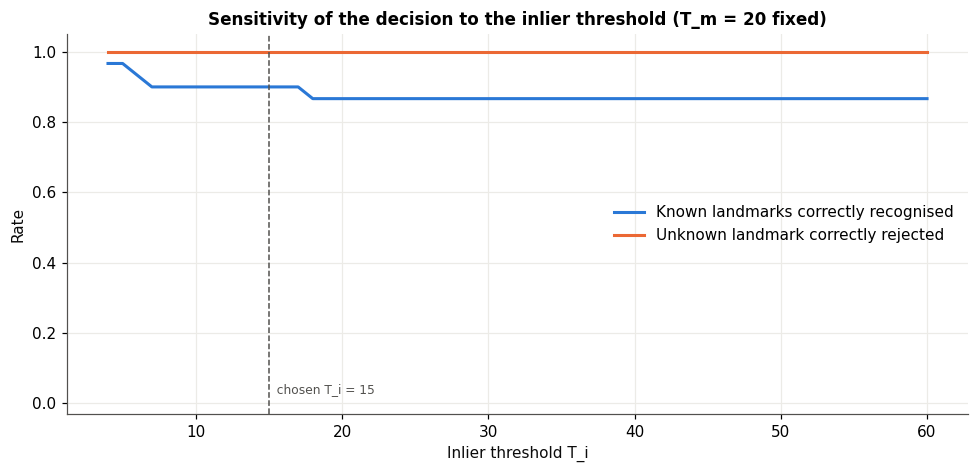

In [23]:
thresholds = np.arange(4, 61, 1)
# Did geometric verification select the TRUE landmark? (independent of the thresholds)
true_selected = np.array([results[i].prediction is not None and nice(results[i].prediction.landmark) == gt
                          for i, gt in zip(known.index, known['Ground truth'])])
recall, unk_reject = [], []
for th in thresholds:
    passes_known = ((known['Reliable matches'] >= MIN_GOOD_MATCHES) & (known['RANSAC inliers'] >= th)).values
    recall.append(np.mean(passes_known & true_selected))
    if len(unknown):
        passes_unk = (unknown['Reliable matches'] >= MIN_GOOD_MATCHES) & (unknown['RANSAC inliers'] >= th)
        unk_reject.append(np.mean(~passes_unk.values))
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(thresholds, recall, color=PALETTE[0], lw=2, label='Known landmarks correctly recognised')
if unk_reject:
    ax.plot(thresholds, unk_reject, color=PALETTE[1], lw=2, label='Unknown landmark correctly rejected')
ax.axvline(MIN_INLIERS, color='#52514e', ls='--', lw=1)
ax.text(MIN_INLIERS, 0.03, f'  chosen T_i = {MIN_INLIERS}', fontsize=8, color='#52514e')
ax.set_xlabel('Inlier threshold T_i'); ax.set_ylabel('Rate'); ax.set_ylim(-0.03, 1.05)
ax.set_title(f'Sensitivity of the decision to the inlier threshold (T_m = {MIN_GOOD_MATCHES} fixed)')
ax.grid(color='#ecebe7', lw=0.8); ax.legend(frameon=False, loc='center right')
fig.tight_layout(); savefig(fig, 'analysis_threshold_sensitivity'); plt.show()

## 13. Results and Interpretation



In [24]:
def describe_results():
    s = summary
    lines = []
    lines.append(f"- Over **{len(results_df)} test queries**, the system made **{results_df['Correct'].sum()} correct decisions** "
                 f"({results_df['Correct'].mean():.0%}). On known landmarks it was correct in "
                 f"**{known['Correct'].sum()}/{len(known)}** cases; the unknown landmark was rejected in "
                 f"**{(unknown['Decision'] == 'Rejected').sum()}/{len(unknown)}** cases.")
    for cond in s.index:
        lines.append(f"- *{cond}*: {s.loc[cond, 'Correct']}/{s.loc[cond, 'Tests']} correct, "
                     f"mean {s.loc[cond, 'Mean reliable matches']:.0f} reliable matches and "
                     f"{s.loc[cond, 'Mean inliers']:.0f} inliers, {s.loc[cond, 'Mean keypoints']:.0f} keypoints.")
    weakest = s.drop(index=[c for c in ['Original', 'Unknown landmark'] if c in s.index])['Mean inliers'].idxmin()
    lines.append(f"- The hardest *known-landmark* condition, measured by mean inliers, was **{weakest}**.")
    errs = results_df[~results_df['Correct']]
    if len(errs):
        lines.append('- Incorrect decisions: ' + '; '.join(
            f"{r['Test']} ({r['Condition']}: {r['Ground truth']} → {r['Predicted landmark']}, "
            f"{r['Reliable matches']} matches / {r['RANSAC inliers']} inliers)"
            for _, r in errs.iterrows()) + '.')
    else:
        lines.append('- No incorrect decisions were made in this run.')
    lines.append(f"- Median processing time was **{results_df['Time (s)'].median():.2f} s** per query against "
                 f"{len(reference_db)} reference images on this machine.")
    display(Markdown('\n'.join(lines)))

describe_results()

- Over **32 test queries**, the system made **29 correct decisions** (91%). On known landmarks it was correct in **27/30** cases; the unknown landmark was rejected in **2/2** cases.
- *Original*: 5/5 correct, mean 1745 reliable matches and 1745 inliers, 1745 keypoints.
- *Rotated*: 5/5 correct, mean 1033 reliable matches and 998 inliers, 1928 keypoints.
- *Resized*: 5/5 correct, mean 346 reliable matches and 342 inliers, 618 keypoints.
- *Low brightness*: 5/5 correct, mean 427 reliable matches and 425 inliers, 460 keypoints.
- *Viewpoint (synthetic)*: 5/5 correct, mean 717 reliable matches and 690 inliers, 1835 keypoints.
- *Viewpoint (real photo)*: 2/5 correct, mean 221 reliable matches and 199 inliers, 1489 keypoints.
- *Unknown landmark*: 2/2 correct, mean 16 reliable matches and 5 inliers, 992 keypoints.
- The hardest *known-landmark* condition, measured by mean inliers, was **Viewpoint (real photo)**.
- Incorrect decisions: T12 (Viewpoint (real photo): Eiffel Tower → REJECTED, 26 matches / 5 inliers); T18 (Viewpoint (real photo): Great Wall of China → REJECTED, 19 matches / 6 inliers); T24 (Viewpoint (real photo): Statue of Liberty → REJECTED, 25 matches / 6 inliers).
- Median processing time was **2.66 s** per query against 25 reference images on this machine.

## 17. Requirement-Compliance Checklist

| # | Requirement (assignment) | Where it is met |
|---|---|---|
| T1 | Database of ≥ 5 famous landmarks | §5 — Eiffel Tower, Taj Mahal, Colosseum, Statue of Liberty, Great Wall; assertion in §5.1 |
| T1 | Multiple images per landmark, different angles/distances | §5 — 5 references per landmark (+1 held-out); contact sheet |
| T1 | Separate folder per landmark | `landmark_db/<Landmark_Name>/` |
| T2.1 | Load each reference image, convert to grayscale | `load_image`, `extract_sift` (§6) |
| T2.2 | Detect SIFT keypoints | `cv2.SIFT_create().detectAndCompute` |
| T2.3 | Extract descriptors | 128-D float32 descriptors, shape asserted |
| T2.4 | Display references with keypoints | §6.1 grid figure (rich keypoints) |
| T2.5 | Store descriptors with labels | `reference_db` + `outputs/sift_descriptor_database.npz` (verified reload) |
| T3.1–3.4 | Load query, grayscale, detect, describe | `process_query` (§7) |
| T3.5 | Display query with keypoints | `show_query` (§7), panel (2) of every result |
| T4.1 | Brute-Force matcher, Euclidean | `cv2.BFMatcher(cv2.NORM_L2)` |
| T4.2 | k-NN with k = 2 | `knnMatch(..., k=2)` |
| T4.3 | Lowe's ratio test | `ratio_test_matches`, τ = 0.75 |
| T4.4 | Count reliable matches per landmark | `rank_landmarks` (best reference per landmark) |
| T4.5 | Rank candidates | sorted ranking, table + bar chart |
| T4.6 | Display most likely landmark + matches | result figure header and panel (4–5) |
| T4 | Threshold to reject unknown; not max-count only | matches ≥ 20 **and** inliers ≥ 15 (§8.3, `recognize`) |
| T5.1 | Corresponding keypoints ref ↔ query | `localize` builds src/dst point arrays |
| T5.2 | Homography with RANSAC when enough matches | `cv2.findHomography(..., cv2.RANSAC, 5.0)`, ≥ 10 matches |
| T5.3 | Project four reference corners | `cv2.perspectiveTransform` |
| T5.4 | Draw polygon | `cv2.polylines`, panel (6) |
| T5.5 | Display reliable matches and inliers | result header, tables |
| T5 | Message instead of invalid polygon | plausibility checks + message in panel (6) |
| T6 | Original / rotated / resized / low-brightness / viewpoint / unknown | §11 — every condition for every landmark (+ synthetic viewpoint) |
| T6 | Record prediction, keypoints, matches, decision, time | `experimental_results.csv`, table §11.2 |
| Output 1–7 | Query, keypoints, matches, name, matches count, localisation, accept/reject message | `show_result` panels (1)–(7) |
| Deliverable | Source code | this notebook (File → Download → .py also available) |
| Deliverable | Organised image database | `landmark_db/`, `queries/` in the submission zip |
| Deliverable | Screenshots of output | `outputs/screenshots/*.png` (one per test + analysis figures) |
| Deliverable | Table of experimental results | §11.2, `outputs/experimental_results.csv` |
| Deliverable | Discussion of performance and limitations | §13, §14 |

## 18. Packaging the Deliverables


In [25]:
zip_path = DATA_ROOT.parent / 'landmark_lab_submission.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(DATA_ROOT.rglob('*')):
        if p.is_file():
            zf.write(p, p.relative_to(DATA_ROOT.parent))
size_mb = zip_path.stat().st_size / 1e6
print(f'{zip_path} — {size_mb:.1f} MB')
for sub in ['landmark_db', 'queries', 'outputs', 'outputs/screenshots']:
    n = len([p for p in (DATA_ROOT / sub).rglob('*') if p.is_file()])
    print(f'  {sub:22s} {n:4d} files')
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))

/content/landmark_lab_submission.zip — 70.2 MB
  landmark_db              25 files
  queries                   7 files
  outputs                  44 files
  outputs/screenshots      41 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>